# Experiment Result Parser

This notebook scans `artifacts/experiments`, picks the latest run for each `scenario/model/modality` combination, and then:

- compares model parameter counts first,
- plots learning history for accuracy and F1,
- builds SI vs SD testing tables from the latest stored metrics.

Latest runs are selected by the newest timestamped run directory name, for example `20260430T003018Z`.

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:.6f}")

PROJECT_ROOT = Path.cwd()
EXPERIMENT_ROOT = PROJECT_ROOT / "artifacts" / "experiments"

if not EXPERIMENT_ROOT.exists():
    raise FileNotFoundError(
        "Expected to run this notebook from the repository root so that 'artifacts/experiments' is available."
    )


def load_json(path: Path) -> dict:
    return json.loads(path.read_text())


def collect_runs(root: Path = EXPERIMENT_ROOT) -> pd.DataFrame:
    rows = []
    for summary_path in sorted(root.glob("*/*/*/*/summary.json")):
        scenario, model, modality, run_id = summary_path.parts[-5:-1]
        summary = load_json(summary_path)
        metrics = summary.get("metrics", {})
        rows.append(
            {
                "scenario": scenario,
                "model": model,
                "modality": modality,
                "run_id": run_id,
                "run_dir": summary.get("run_dir", str(summary_path.parent)),
                "summary_path": str(summary_path),
                "history_path": str(summary_path.with_name("history.json")),
                "metrics_path": str(summary_path.with_name("metrics.json")),
                "parameter_count": summary.get("parameter_count"),
                "input_shape": tuple(summary.get("input_shape", [])),
                "train_size": summary.get("train_size"),
                "test_size": summary.get("test_size"),
                "num_classes": summary.get("num_classes"),
                "test_accuracy": metrics.get("accuracy"),
                "test_f1_score": metrics.get("f1_score"),
                "test_loss": metrics.get("loss"),
            }
        )
    frame = pd.DataFrame(rows)
    if frame.empty:
        raise ValueError(f"No experiment summaries found under {root}")
    frame = frame.sort_values(["scenario", "model", "modality", "run_id"]).reset_index(drop=True)
    return frame


all_runs = collect_runs()
latest_runs = (
    all_runs.sort_values("run_id")
    .groupby(["scenario", "model", "modality"], as_index=False)
    .tail(1)
    .sort_values(["scenario", "model", "modality"])
    .reset_index(drop=True)
)

latest_runs.insert(3, "combination", latest_runs["model"] + " | " + latest_runs["modality"])

display(latest_runs)


,scenario,model,modality,combination,run_id,run_dir,summary_path,history_path,metrics_path,parameter_count,input_shape,train_size,test_size,num_classes,test_accuracy,test_f1_score,test_loss
0,sd,cnn1d,hand,cnn1d | hand,20260429T234942Z,artifacts/experiments/sd/cnn1d/hand/20260429T2...,/app/artifacts/experiments/sd/cnn1d/hand/20260...,/app/artifacts/experiments/sd/cnn1d/hand/20260...,/app/artifacts/experiments/sd/cnn1d/hand/20260...,498859,"(10, 210)",50456,32943,2731,0.010715,0.002445,6.645147
1,sd,gcn,hand,gcn | hand,20260430T004416Z,artifacts/experiments/sd/gcn/hand/20260430T004...,/app/artifacts/experiments/sd/gcn/hand/2026043...,/app/artifacts/experiments/sd/gcn/hand/2026043...,/app/artifacts/experiments/sd/gcn/hand/2026043...,381427,"(10, 210)",50456,32943,2731,0.020126,0.009262,6.280019
2,sd,lstm,hand,lstm | hand,20260430T000512Z,artifacts/experiments/sd/lstm/hand/20260430T00...,/app/artifacts/experiments/sd/lstm/hand/202604...,/app/artifacts/experiments/sd/lstm/hand/202604...,/app/artifacts/experiments/sd/lstm/hand/202604...,880299,"(10, 210)",50456,32943,2731,0.005828,0.000725,6.814507
3,sd,transformer,hand,transformer | hand,20260430T003018Z,artifacts/experiments/sd/transformer/hand/2026...,/app/artifacts/experiments/sd/transformer/hand...,/app/artifacts/experiments/sd/transformer/hand...,/app/artifacts/experiments/sd/transformer/hand...,1039787,"(10, 210)",50456,32943,2731,0.203473,0.179652,4.064089
4,si,cnn1d,hand,cnn1d | hand,20260430T005801Z,artifacts/experiments/si/cnn1d/hand/20260430T0...,/app/artifacts/experiments/si/cnn1d/hand/20260...,/app/artifacts/experiments/si/cnn1d/hand/20260...,/app/artifacts/experiments/si/cnn1d/hand/20260...,498859,"(10, 210)",50458,32941,2731,0.011596,0.003146,6.698225
5,si,gcn,hand,gcn | hand,20260430T015105Z,artifacts/experiments/si/gcn/hand/20260430T015...,/app/artifacts/experiments/si/gcn/hand/2026043...,/app/artifacts/experiments/si/gcn/hand/2026043...,/app/artifacts/experiments/si/gcn/hand/2026043...,381427,"(10, 210)",50458,32941,2731,0.023648,0.011182,6.264698
6,si,lstm,hand,lstm | hand,20260430T011155Z,artifacts/experiments/si/lstm/hand/20260430T01...,/app/artifacts/experiments/si/lstm/hand/202604...,/app/artifacts/experiments/si/lstm/hand/202604...,/app/artifacts/experiments/si/lstm/hand/202604...,880299,"(10, 210)",50458,32941,2731,0.008318,0.001654,6.686659
7,si,transformer,hand,transformer | hand,20260430T013655Z,artifacts/experiments/si/transformer/hand/2026...,/app/artifacts/experiments/si/transformer/hand...,/app/artifacts/experiments/si/transformer/hand...,/app/artifacts/experiments/si/transformer/hand...,1039787,"(10, 210)",50458,32941,2731,0.197596,0.177917,4.184962


,model,modality,scenario,parameter_count,input_shape,num_classes
0,transformer,hand,sd,1039787,"(10, 210)",2731
1,transformer,hand,si,1039787,"(10, 210)",2731
2,lstm,hand,sd,880299,"(10, 210)",2731
3,lstm,hand,si,880299,"(10, 210)",2731
4,cnn1d,hand,sd,498859,"(10, 210)",2731
5,cnn1d,hand,si,498859,"(10, 210)",2731
6,gcn,hand,sd,381427,"(10, 210)",2731
7,gcn,hand,si,381427,"(10, 210)",2731


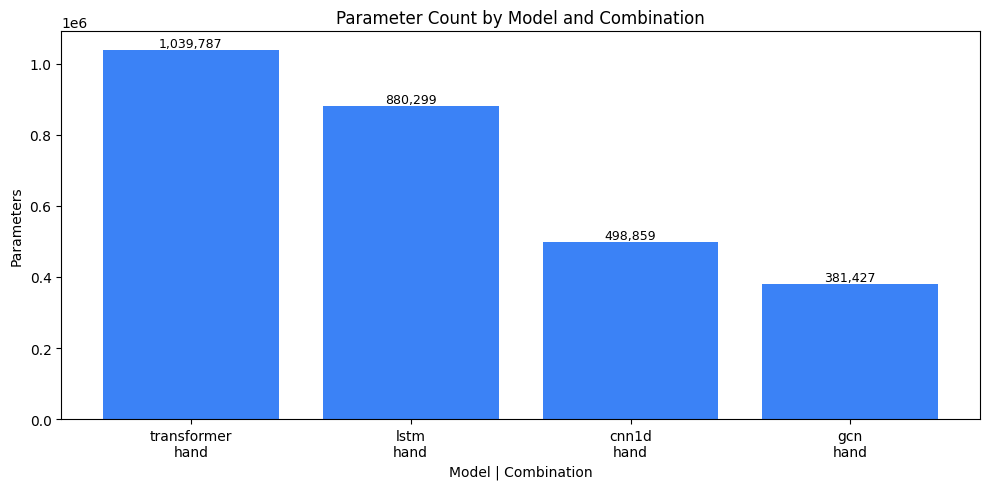

In [2]:
# Parameter comparison first
parameter_table = (
    latest_runs[["model", "modality", "scenario", "parameter_count", "input_shape", "num_classes"]]
    .sort_values(["parameter_count", "model", "modality", "scenario"], ascending=[False, True, True, True])
    .reset_index(drop=True)
)
display(parameter_table)

parameter_plot = (
    latest_runs[["model", "modality", "parameter_count"]]
    .drop_duplicates()
    .sort_values("parameter_count", ascending=False)
)
parameter_plot["label"] = parameter_plot["model"] + "\n" + parameter_plot["modality"]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(parameter_plot["label"], parameter_plot["parameter_count"], color="#3b82f6")
ax.set_title("Parameter Count by Model and Combination")
ax.set_ylabel("Parameters")
ax.set_xlabel("Model | Combination")
ax.tick_params(axis="x", rotation=0)
for index, value in enumerate(parameter_plot["parameter_count"]):
    ax.text(index, value, f"{value:,}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()


,scenario,model,modality,series,run_id,epoch,split,metric,value
0,sd,cnn1d,hand,cnn1d | hand,20260429T234942Z,1,train,accuracy,0.000277
1,sd,cnn1d,hand,cnn1d | hand,20260429T234942Z,2,train,accuracy,0.000297
2,sd,cnn1d,hand,cnn1d | hand,20260429T234942Z,3,train,accuracy,0.000753
3,sd,cnn1d,hand,cnn1d | hand,20260429T234942Z,4,train,accuracy,0.000793
4,sd,cnn1d,hand,cnn1d | hand,20260429T234942Z,5,train,accuracy,0.001546


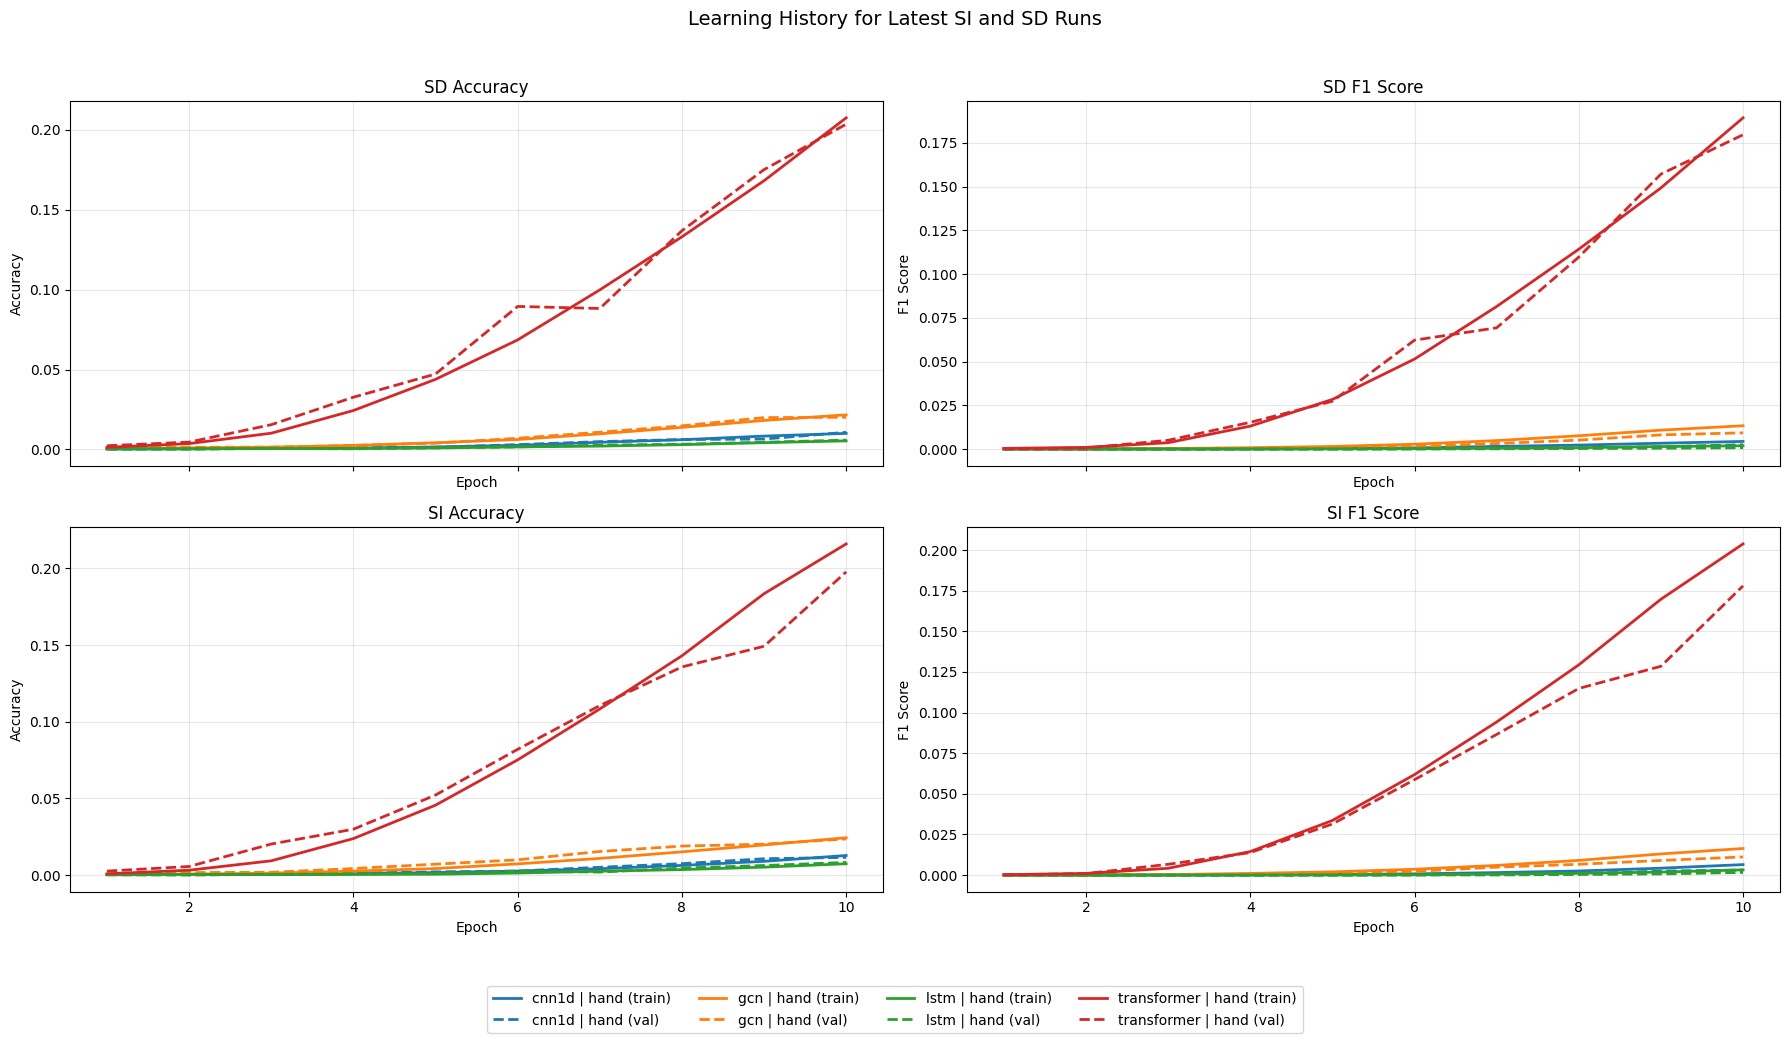

In [3]:
def build_history_frame(latest_frame: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for run in latest_frame.itertuples(index=False):
        history = load_json(PROJECT_ROOT / run.history_path)
        keys = {
            ("train", "accuracy"): "accuracy",
            ("val", "accuracy"): "val_accuracy",
            ("train", "f1_score"): "f1_score",
            ("val", "f1_score"): "val_f1_score",
        }
        for (split, metric), history_key in keys.items():
            values = history.get(history_key, [])
            for epoch, value in enumerate(values, start=1):
                rows.append(
                    {
                        "scenario": run.scenario,
                        "model": run.model,
                        "modality": run.modality,
                        "series": f"{run.model} | {run.modality}",
                        "run_id": run.run_id,
                        "epoch": epoch,
                        "split": split,
                        "metric": metric,
                        "value": value,
                    }
                )
    return pd.DataFrame(rows)


history_df = build_history_frame(latest_runs)
display(history_df.head())

scenario_order = [scenario for scenario in ["sd", "si"] if scenario in set(history_df["scenario"])]
if len(scenario_order) != 2:
    raise ValueError(f"Expected both SD and SI histories for a 2x2 comparison, found: {scenario_order}")

metric_specs = [("accuracy", "Accuracy"), ("f1_score", "F1 Score")]
all_series = sorted(history_df["series"].unique())
color_map = {
    series_name: plt.cm.tab10(index % 10)
    for index, series_name in enumerate(all_series)
}

fig, axes = plt.subplots(2, 2, figsize=(18, 10), sharex=True)
legend_handles = {}

for row_index, scenario in enumerate(scenario_order):
    scenario_history = history_df[history_df["scenario"] == scenario].copy()
    series_names = sorted(scenario_history["series"].unique())

    for col_index, (metric_name, title) in enumerate(metric_specs):
        ax = axes[row_index, col_index]
        metric_history = scenario_history[scenario_history["metric"] == metric_name]

        for series_name in series_names:
            series_history = metric_history[metric_history["series"] == series_name]
            for split, linestyle in [("train", "-"), ("val", "--")]:
                line_history = series_history[series_history["split"] == split]
                if line_history.empty:
                    continue
                label = f"{series_name} ({split})"
                line, = ax.plot(
                    line_history["epoch"],
                    line_history["value"],
                    color=color_map[series_name],
                    linestyle=linestyle,
                    linewidth=2,
                    label=label,
                )
                legend_handles.setdefault(label, line)

        ax.set_title(f"{scenario.upper()} {title}")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(title)
        ax.grid(alpha=0.3)

fig.legend(
    legend_handles.values(),
    legend_handles.keys(),
    loc="lower center",
    ncol=4,
    bbox_to_anchor=(0.5, -0.01),
)
fig.suptitle("Learning History for Latest SI and SD Runs", y=1.02, fontsize=14)
fig.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()


In [4]:
# Testing comparison tables for the latest SI and SD runs
test_results_long = (
    latest_runs[[
        "scenario",
        "model",
        "modality",
        "run_id",
        "test_accuracy",
        "test_f1_score",
        "test_loss",
        "test_size",
    ]]
    .sort_values(["scenario", "model", "modality"])
    .reset_index(drop=True)
)
display(test_results_long)

test_results_compare = (
    latest_runs.pivot_table(
        index=["model", "modality"],
        columns="scenario",
        values=["test_accuracy", "test_f1_score", "test_loss", "run_id"],
        aggfunc="first",
    )
    .swaplevel(0, 1, axis=1)
    .sort_index(axis=1, level=[0, 1])
)
display(test_results_compare)

best_by_scenario = (
    latest_runs.sort_values(["scenario", "test_accuracy", "test_f1_score"], ascending=[True, False, False])
    .groupby("scenario", as_index=False)
    
    [["scenario", "model", "modality", "run_id", "test_accuracy", "test_f1_score", "test_loss"]]
)
display(best_by_scenario)

selected_runs = latest_runs[["scenario", "model", "modality", "run_id", "run_dir"]].copy()
display(selected_runs)


,scenario,model,modality,run_id,test_accuracy,test_f1_score,test_loss,test_size
0,sd,cnn1d,hand,20260429T234942Z,0.010715,0.002445,6.645147,32943
1,sd,gcn,hand,20260430T004416Z,0.020126,0.009262,6.280019,32943
2,sd,lstm,hand,20260430T000512Z,0.005828,0.000725,6.814507,32943
3,sd,transformer,hand,20260430T003018Z,0.203473,0.179652,4.064089,32943
4,si,cnn1d,hand,20260430T005801Z,0.011596,0.003146,6.698225,32941
5,si,gcn,hand,20260430T015105Z,0.023648,0.011182,6.264698,32941
6,si,lstm,hand,20260430T011155Z,0.008318,0.001654,6.686659,32941
7,si,transformer,hand,20260430T013655Z,0.197596,0.177917,4.184962,32941


scenario                            sd                                        \
                                run_id test_accuracy test_f1_score test_loss   
model       modality                                                           
cnn1d       hand      20260429T234942Z      0.010715      0.002445  6.645147   
gcn         hand      20260430T004416Z      0.020126      0.009262  6.280019   
lstm        hand      20260430T000512Z      0.005828      0.000725  6.814507   
transformer hand      20260430T003018Z      0.203473      0.179652  4.064089   

scenario                            si                                        
                                run_id test_accuracy test_f1_score test_loss  
model       modality                                                          
cnn1d       hand      20260430T005801Z      0.011596      0.003146  6.698225  
gcn         hand      20260430T015105Z      0.023648      0.011182  6.264698  
lstm        hand      20260430T011155Z      0.008318      0.001654  6.686659  
transformer hand      20260430T013655Z      0.197596      0.177917  4.184962

,scenario,model,modality,run_id,run_dir
0,sd,cnn1d,hand,20260429T234942Z,artifacts/experiments/sd/cnn1d/hand/20260429T2...
1,sd,gcn,hand,20260430T004416Z,artifacts/experiments/sd/gcn/hand/20260430T004...
2,sd,lstm,hand,20260430T000512Z,artifacts/experiments/sd/lstm/hand/20260430T00...
3,sd,transformer,hand,20260430T003018Z,artifacts/experiments/sd/transformer/hand/2026...
4,si,cnn1d,hand,20260430T005801Z,artifacts/experiments/si/cnn1d/hand/20260430T0...
5,si,gcn,hand,20260430T015105Z,artifacts/experiments/si/gcn/hand/20260430T015...
6,si,lstm,hand,20260430T011155Z,artifacts/experiments/si/lstm/hand/20260430T01...
7,si,transformer,hand,20260430T013655Z,artifacts/experiments/si/transformer/hand/2026...
